Thư viện

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, i0
from scipy.integrate import quad
import trace
import sys

Thông Số

In [45]:
f_c = 12
d = 36000
BW = 1e6
G_tx = 30
G_rx = 30
T_sys = 250
k_boltz = 1.38e-23
num_bits = 100000
K_factor_dB = 10
P_tx_dBW_range = np.arange(0, 15, 1)


Tính thông số

In [46]:
FSPL_dB = 92.44 + 20 * np.log10(f_c) + 20 * np.log10(d)
K_factor = 10 ** (K_factor_dB / 10)
N_noise_watts = k_boltz * T_sys * BW
N_noise_dBW = 10 * np.log10(N_noise_watts)
print(f"FSPL (dB): {FSPL_dB:.2f}")
print(f"Noise Power (dBW): {N_noise_dBW:.2f}")

FSPL (dB): 205.15
Noise Power (dBW): -144.62


BER Lý thuyết

In [25]:
def calculate_rician_theory_exact(snr_db_list, K_linear):
    K = K_linear
    ber_results = []

    def rician_pdf(r):
        if r < 0:
            return 0.0
        result = 2.0 * r * (K + 1.0) * np.exp(-K - (K + 1.0) * r**2) * i0(2.0 * r * np.sqrt(K * (K + 1.0)))
        return result if np.isfinite(result) else 0.0

    for snr_val_db in snr_db_list:
        snr_linear = 10 ** (snr_val_db / 10)
        integrand = lambda r: 0.5 * erfc(np.sqrt(snr_linear / 2.0) * r) * rician_pdf(r)
        val, err = quad(integrand, 0, np.inf, epsabs=1e-8, epsrel=1e-6, limit=300)

        if np.isfinite(val) and 0 <= val <= 1:
            ber_results.append(val)
            print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: {val:.6e}")
        else:
            ber_results.append(0.5)
            print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: INVALID -> set to 0.5")

    return ber_results



Mô Phỏng

In [ ]:
def run_simulation():
    print(f"--- [3/4] BẮT ĐẦU MÔ PHỎNG (K={K_factor_dB} dB) ---")
    sim_ber = []
    EPS = 1e-12

    for P_tx in P_tx_dBW_range:
        P_rx = P_tx + G_tx + G_rx - FSPL_dB
        SNR_dB = P_rx - N_noise_dBW
        SNR_linear = 10 ** (SNR_dB / 10)

        bits = np.random.randint(0, 2, num_bits)
        symbols_tx = (2 * bits[0::2] - 1) + 1j * (2 * bits[1::2] - 1)
        symbols_tx = symbols_tx / np.sqrt(2)

        num_symbols = len(symbols_tx)
        K = 10 ** (K_factor_dB / 10)
        mu = np.sqrt(K / (K + 1))
        sigma = np.sqrt(1.0 / (2.0 * (K + 1.0)))

        ber_c = []
        for ch in range(1000):
            delta_mu = 0.01
            A_LOS = mu * (1 + delta_mu * np.random.randn())
            phi_LOS = 2 * np.pi * np.random.rand()
            h_LOS = A_LOS * np.exp(1j * phi_LOS)

            h_NLOS = sigma * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))

            h = h_LOS + h_NLOS

            y_faded = h * symbols_tx

            noise_power = 1.0 / SNR_linear
            noise = np.sqrt(noise_power / 2.0) * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
            y_received = y_faded + noise

            h_safe = np.where(np.abs(h) < EPS, EPS, h)
            y_equalized = y_received / h_safe

            bits_rx = np.zeros(num_bits, dtype=int)
            bits_rx[0::2] = (np.real(y_equalized) > 0).astype(int)
            bits_rx[1::2] = (np.imag(y_equalized) > 0).astype(int)

            ber = np.sum(bits != bits_rx) / num_bits
            ber_c.append(ber)

        ber = np.mean(ber_c)
        sim_ber.append(ber)
        print(f"   P_tx: {P_tx:2d} dBW | SNR: {SNR_dB:6.2f} dB | BER Sim: {ber:.6e}")

    return sim_ber


Mô Phỏng

In [47]:
SNR_range_theory = P_tx_dBW_range + G_tx + G_rx - FSPL_dB - N_noise_dBW

theory_ber = calculate_rician_theory_exact(SNR_range_theory, 10)
sim_ber = run_simulation()

C:\Users\sang8\AppData\Local\Temp\ipykernel_15936\2676762702.py:8: RuntimeWarning: invalid value encountered in scalar multiply
  result = 2.0 * r * (K + 1.0) * np.exp(-K - (K + 1.0) * r**2) * i0(2.0 * r * np.sqrt(K * (K + 1.0)))


   SNR:  -0.53 dB | BER Theory: 1.834052e-01
   SNR:   0.47 dB | BER Theory: 1.568047e-01
   SNR:   1.47 dB | BER Theory: 1.305446e-01
   SNR:   2.47 dB | BER Theory: 1.053719e-01
   SNR:   3.47 dB | BER Theory: 8.207351e-02
   SNR:   4.47 dB | BER Theory: 6.138291e-02
   SNR:   5.47 dB | BER Theory: 4.386780e-02
   SNR:   6.47 dB | BER Theory: 2.982687e-02
   SNR:   7.47 dB | BER Theory: 1.923169e-02
   SNR:   8.47 dB | BER Theory: 1.174187e-02
   SNR:   9.47 dB | BER Theory: 6.795518e-03
   SNR:  10.47 dB | BER Theory: 3.743592e-03
   SNR:  11.47 dB | BER Theory: 1.978077e-03
   SNR:  12.47 dB | BER Theory: 1.013484e-03
   SNR:  13.47 dB | BER Theory: 5.103192e-04
--- [3/4] BẮT ĐẦU MÔ PHỎNG (K=10 dB) ---
   P_tx:  0 dBW | SNR:  -0.53 dB | BER Sim: 1.834240e-01
   P_tx:  1 dBW | SNR:   0.47 dB | BER Sim: 1.568356e-01
   P_tx:  2 dBW | SNR:   1.47 dB | BER Sim: 1.305370e-01
   P_tx:  3 dBW | SNR:   2.47 dB | BER Sim: 1.053773e-01
   P_tx:  4 dBW | SNR:   3.47 dB | BER Sim: 8.208309e-02

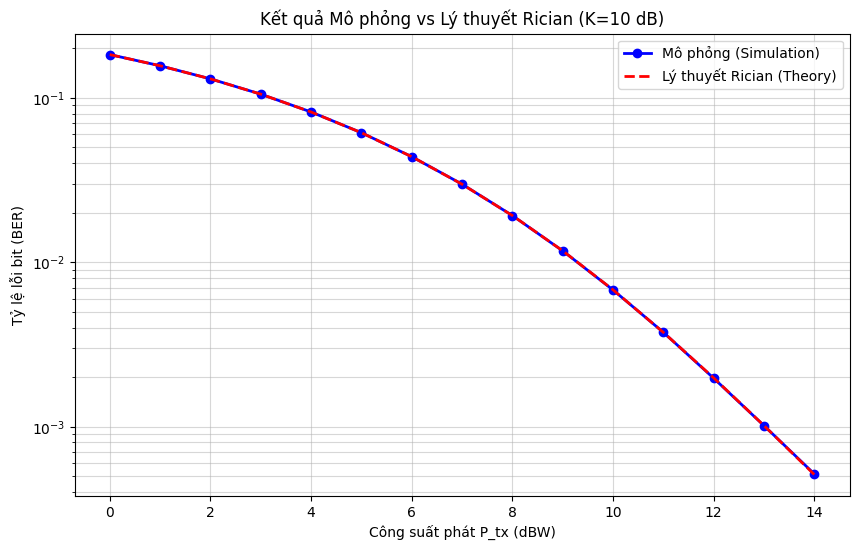

In [48]:
plt.figure(figsize=(10, 6))
plt.semilogy(P_tx_dBW_range, sim_ber, 'bo-', markersize=6, linewidth=2, label='Mô phỏng (Simulation)')
plt.semilogy(P_tx_dBW_range, theory_ber, 'r--', linewidth=2, label='Lý thuyết Rician (Theory)')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.xlabel('Công suất phát P_tx (dBW)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title(f'Kết quả Mô phỏng vs Lý thuyết Rician (K={K_factor_dB} dB)')
plt.legend()